 # Getting Started 

### <i> Roadscanners Frostbumps Data Training


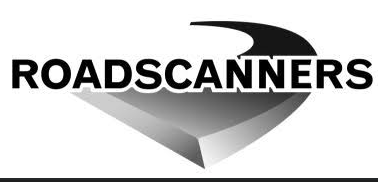

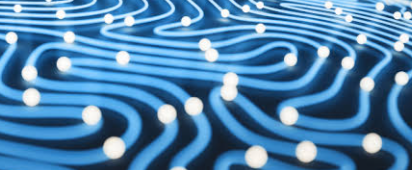

 ###  <i> Summary


This is a notebook to help you get started with training a model using RoadScanners Frostbumps datasets.

This approach combines six datasets for training, and leaves one dataset for the test split. 


This serves as a starting point for you to experiment using `keras` LSTM. 

<br>
<br>

<strong style='color:teal ; background-color:black;'> This notebook will give you a START, it will not give you a well performing model. </strong>

##### <i> Dependencies

In [1]:
# %pip install pydot keras seaborn matplotlib pandas scikit-learn

---

### <i> Loading all the cleaned datasets

This is going to be a concatenated approach instead of temporally splitting each individual dataset 
categorized by speed. There's multiple approaches for this. This doesn't mean this is the best way, just a simple way
to get started.

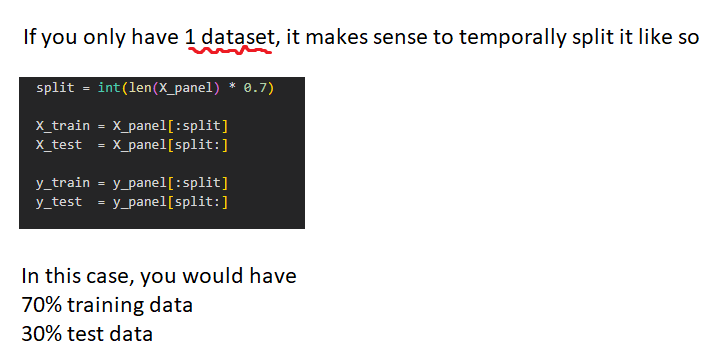

<br>

Of course, how you split that could be 80 20, or 70 10 10 -- Your perogative.

<br>

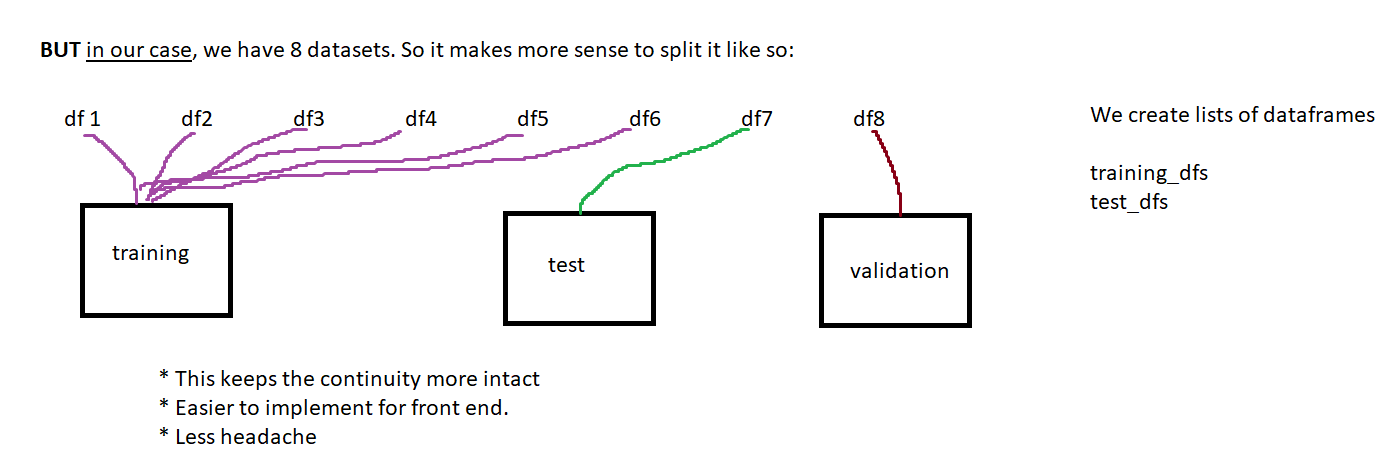

<br>

Naturally, if you're planning to split this by speeds it becomes more complicated

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import keras
from keras import layers
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Reading all the cleaned datasets (minus one).
df_00 = pd.read_csv(
    r"C:\frostbumps2026\00_cleaned_Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.csv",
    index_col = 0
)
df_01 = pd.read_csv(
    r"C:\frostbumps2026\01_cleaned_Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.csv",
    index_col = 0
)
df_02 = pd.read_csv(
    r"C:\frostbumps2026\02_Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.csv",
    index_col = 0
)
df_04 = pd.read_csv(
    r"C:\frostbumps2026\04_cleaned_sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.csv",
    index_col = 0
)
df_05 = pd.read_csv(
    r"C:\frostbumps2026\05_cleaned_sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.csv",
    index_col = 0
)
df_06 = pd.read_csv(
    r"c:\frostbumps2026\06_cleaned_sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.csv",
    index_col = 0
)
df_07 = pd.read_csv(
    r"c:\frostbumps2026\07_cleaned_sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.csv",
    index_col = 0
)

# Dropping the dataleak columns
df_01 = df_01.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_00 = df_00.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)" ], axis=1)
df_02 = df_02.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_04 = df_04.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_05 = df_05.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_06 = df_06.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)
df_07 = df_07.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)", "Yaw(deg)"], axis=1)

# Now we split the datasets themselves instead of temporally splitting.
train_dfs = [df_00, df_02, df_01, df_05, df_06, df_07]
test_dfs = [df_04]

df_01

,Timer(ms),Loc(m),Speed (m/s),CElev(m),Roll(deg),Pitch(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Frostbumps
6000,45911356.5,3779.080,6.745,109.100,-0.5181,-5.2698,2.29698,-0.14429,9.24408,0.00221,0.00812,-0.01797,2.08915,0
6001,45911359.0,3779.097,6.750,109.100,-0.5174,-5.2695,2.28205,-0.08029,9.29178,-0.00078,0.00771,-0.01984,2.08398,0
6002,45911361.5,3779.114,6.755,109.100,-0.5155,-5.2699,2.30077,-0.04737,9.33804,0.00747,0.00288,-0.01840,2.07660,0
6003,45911364.0,3779.131,6.760,109.100,-0.5137,-5.2698,2.37089,-0.09478,9.45296,0.00634,0.00669,-0.02373,2.07218,0
6004,45911366.5,3779.148,6.765,109.100,-0.5135,-5.2689,2.35204,-0.05549,9.52185,-0.00460,0.01177,-0.02303,2.06696,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83592,46105337.4,6910.462,7.753,119.601,2.5315,-3.0370,-1.88428,0.21240,9.64411,-0.01138,-0.00057,-0.00476,0.21548,0
83593,46105339.9,6910.481,7.753,119.601,2.5313,-3.0349,-2.08760,0.48818,9.84319,-0.00640,0.01543,-0.00437,0.21556,0
83594,46105342.4,6910.500,7.753,119.601,2.5311,-3.0331,-2.34885,0.42224,10.22482,-0.00644,0.01380,-0.00492,0.21558,0
83595,46105344.9,6910.520,7.754,119.601,2.5305,-3.0328,-2.34571,0.56560,10.09793,-0.00986,0.00253,-0.00771,0.21553,0


---

### <i> Functions

We're going to create two functions to help us.



|Function| Description|
|---|---|
|`make_panels()`|This will create the temporal, 3D pandas panels for us.|
|`combine_panels()`|In case you're combining multiple datasets at once.|


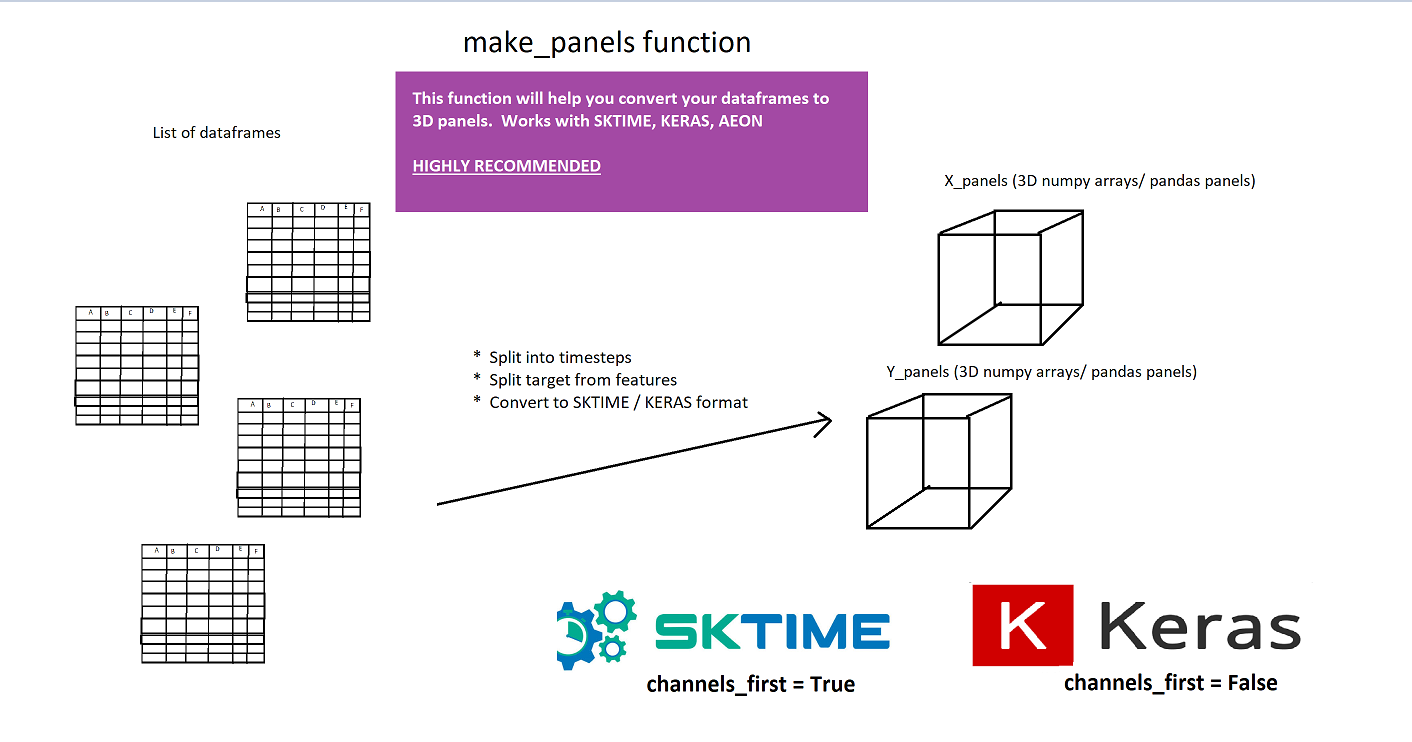

`make_panels()` is there to prevent us from having a headache converting datasets to a 3D numpy array/ pandas panels no matter what approach you're using.

<br>

ALTERNATIVELY, you could use `sktime`'s panel converter method: `from_3d_numpy_to_multi_index`, which is more complicated and only works for `sktime`


In [3]:
'''
Returns two pandas 3D panels, split as X y which are sktime library-compliant
data structures used for machine learning models. The time step is determined
by the `sequence length`. 

dfs             = list of pandas dataframes; these are the dataframes to be converted.
sequence_length = int; time-step, determines the temporal step in rows.
target_column   = string; the name of the target column
channels_first  = boolean; default is (samples,features,timesteps), otherwise
                  it is (samples, timesteps, features)
'''
def make_panels(dfs, sequence_length, target_column, channels_first=True):

    X_panels = {}
    y_panels = {}

    for i, df in enumerate(dfs):

        X = df.drop(target_column, axis=1).to_numpy()
        y = df[target_column].to_numpy()

        n_sequences = len(X) // sequence_length

        X = X[:n_sequences * sequence_length]
        y = y[:n_sequences * sequence_length]

        X_panel = X.reshape(
            n_sequences,
            sequence_length,
            X.shape[1]
        )

        # This portion changes the shape of the model depending on
        # your needs. sktime uses `True`, neural networks uses `False`
        if channels_first:
            X_panel = X_panel.transpose(0, 2, 1)

        y_panel = y.reshape(
            n_sequences,
            sequence_length
        )[:, -1]

        X_panels[i] = X_panel
        y_panels[i] = y_panel

    return X_panels, y_panels


'''
Combines lists of pandas panels to a singular X y concatenated
list of values, necessary before inserting it to any ml
models.

X_panels   = list of pandas sequential panels: Features. 
y_panels   = list of pandas sequential panels: For the target variable. 
'''
def combine_panels(X_panels, y_panels):

    X = np.concatenate(
        list(X_panels.values()),
        axis=0
    )

    y = np.concatenate(
        list(y_panels.values()),
        axis=0
    )

    return X, y

---

### <i> Model Training Prep


Now, let's use the functions above to split the data, create the panels, and scale the data.


In [4]:
# CHANGE THIS NUMBER TO CHANGE THE TIMESTEP
sequence_length = 54

# Create training panels
X_train_panels, y_train_panels = make_panels(
    train_dfs,
    sequence_length,
    "Frostbumps",
    channels_first=False
)

# Create test panels
X_test_panels, y_test_panels = make_panels(
    test_dfs,
    sequence_length,
    "Frostbumps",
    channels_first=False
)

# Combining the panels
X_train, y_train = combine_panels(X_train_panels, y_train_panels)
X_test, y_test = combine_panels(X_test_panels, y_test_panels)

# Set appropriate data types (Keras needs this, it doesn't like float64)
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# from scipy.signal import savgol_filter

# # helper function, SavGol -filter
# def savitzky_golay_filter(X, window_length=14, polyorder=7):
#     # apply Savitzky-Golay filter to smooth and denoise the time series data
#     return savgol_filter(X, window_length=window_length, polyorder=polyorder, axis=2)

# X_train_sg = savitzky_golay_filter(X_train)
# X_test_sg = savitzky_golay_filter(X_test)

# Scaling. 
# Flattening the sequences to 2D --> transforming it --> 3D
# NOTE for me: I probably could have flattened it at the beginning. 
scaler = StandardScaler()
n_features = X_train.shape[2]
X_train_scaled = scaler.fit_transform(X_train.reshape(-1, n_features)).reshape(X_train.shape)
X_test_scaled = scaler.transform(X_test.reshape(-1, n_features)).reshape(X_test.shape)

In [5]:
# # visualize a comparison between original and a smoothed esxample signal
# plt.figure(figsize=(12, 6))
# plt.subplot(2, 2, 1)
# plt.plot(X_train[0, 0], label="Original")
# plt.title("Original Signal")
# plt.subplot(2, 2, 2)
# plt.plot(X_train_sg[0, 0], label="Savitzky-Golay Filtered")
# plt.title("Savitzky-Golay Filtered")
# plt.tight_layout()
# plt.show()

In [6]:
# X_train = X_train_sg
# X_test = X_test_sg

In [7]:
X_train.shape

(6217, 54, 13)

In [8]:

import numpy as np
import keras
from keras import layers
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Setting the keras random seed
keras.utils.set_random_seed(1995)

# Fixed training / validation split + Shuffling!
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)


# Class weights. 
# NOTE: These are virtually non-negotiable to have, since the distributions
# Where frostbumps == 0 and 1 is completely uneven. You can also add your own class_weight
# system and give that a shot!
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))
num_classes = 2



# A VERY VERY simple LSTM, highly recommended to experiment with 
# more layers, input sizes, etc. 
def make_model(input_shape):

    model = keras.Sequential([

        # input layer
        keras.layers.Input(input_shape),

        # convolutional layer 1 (we usually have 1-3 convolutional layers
        # depending how much and how complex the data is) -> "model capacity / decision space"
        keras.layers.Conv1D(filters=96, kernel_size=3, padding="same"),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),

        keras.layers.Conv1D(filters=96, kernel_size=3, padding="same"),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),

        keras.layers.Conv1D(filters=64, kernel_size=3, padding="same"),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),

        keras.layers.Conv1D(filters=64, kernel_size=3, padding="same"),
        keras.layers.BatchNormalization(),
        keras.layers.ReLU(),


        # pooling + flatten (adapter from convolutional to dense)
        # flattening is done only once after the final convolutional layer 
        # and before the Dense-network
        keras.layers.GlobalAveragePooling1D(),
        keras.layers.Flatten(),

        # neural network Dense-tail
        keras.layers.Dense(64, activation="relu"),

        # output layer
        keras.layers.Dense(num_classes, activation="softmax")

        # # Defines the expected input shape (timesteps, features).
        # layers.Input(shape=input_shape),

        # # LSTM layer with 64 neurons.
        # layers.LSTM(64),

        # # Batch normalization to speed up training.
        # layers.BatchNormalization(),

        # # Randomly disables 20% of neurons during training.
        # layers.Dropout(0.2),

        # # Connected layer with 32 neurons.
        # layers.Dense(32, activation="relu"),

        # # Further reduces overfitting by randomly disabling 20% of neurons.
        # layers.Dropout(0.2),

        # # Output layer with one neuron per class.
        # # Softmax converts the outputs into probabilities that sum to 1.
        # layers.Dense(num_classes, activation="softmax")
    ])

    return model



# Compile model
model = make_model(input_shape=X_train.shape[1:])
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Callbacks
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    "best_model_frostbump.keras", save_best_only=True, monitor="val_loss"
),

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr,model_checkpoint],
    class_weight=class_weights,
    # class_weight={0: 1.0, 1: 10.0},
    shuffle=True
)

Epoch 1/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8060 - loss: 0.4177 - val_accuracy: 0.8682 - val_loss: 0.3326 - learning_rate: 5.0000e-04
Epoch 2/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8476 - loss: 0.3312 - val_accuracy: 0.8762 - val_loss: 0.2969 - learning_rate: 5.0000e-04
Epoch 3/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8733 - loss: 0.2870 - val_accuracy: 0.8730 - val_loss: 0.3259 - learning_rate: 5.0000e-04
Epoch 4/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8928 - loss: 0.2496 - val_accuracy: 0.8746 - val_loss: 0.3022 - learning_rate: 5.0000e-04
Epoch 5/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9085 - loss: 0.2239 - val_accuracy: 0.8810 - val_loss: 0.3064 - learning_rate: 5.0000e-04
Epoch 6/100
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9194 - loss: 0.1982 - val_accuracy: 0.8714 - val_loss: 0.3213 - learning_rate: 5.0000e-04
Epoch 7/100
155/156 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step -

In [9]:
class_weights

{np.int64(0): np.float64(0.6310913705583756),
 np.int64(1): np.float64(2.4070667957405614)}

In [10]:
model = keras.models.load_model("best_model_frostbump.keras")

---

### <i> Metrics

##### <i> Classification report

In [11]:
# Additional metrics ONLY for classification
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, roc_auc_score

from sklearn.metrics import classification_report

# Predict probabilities
y_prob = model.predict(X_test_scaled, verbose=0)

# Convert probabilities into class predictions
y_pred = np.argmax(y_prob, axis=1)

# Performance metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob[:, 1]):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6311
ROC-AUC:  0.9221

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.98      0.68        41
           1       0.96      0.40      0.57        62

    accuracy                           0.63       103
   macro avg       0.74      0.69      0.62       103
weighted avg       0.79      0.63      0.61       103



##### <i> Confusion Matrix

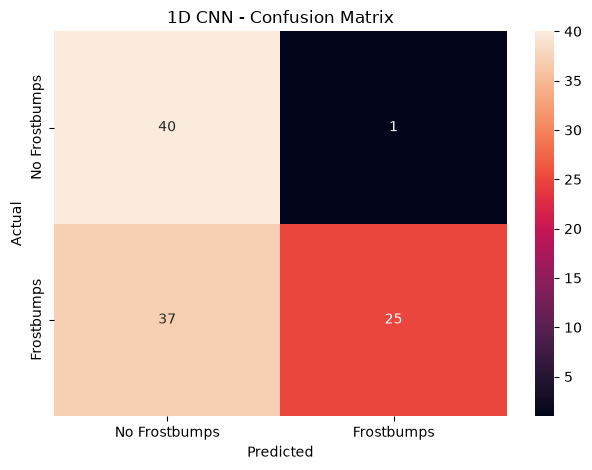

In [12]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])


# Seaborn visualization
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Frostbumps", "Frostbumps"],
    yticklabels=["No Frostbumps", "Frostbumps"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("1D CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

---

### <i> Tester Panels

In Tuomas' lectures, we had synthetically created tester rows. 

<br>
<br>

However, it is VERY impractical to create synthetic data with time-series since you would have to make as many rows as your timestep instead of just 1 and also have to recreate realistic, complex relationships between that data.

<br>
<br>

Therefore, we're going to use our validation dataset as our tester row instead.

<br>
<br>

#### Tester row where `Frostbumps = 1` .


In [13]:
# Creating a tester row to check if it works as expected. 

# Let's load our validation dataset.
test_df = pd.read_csv(
    r"C:\frostbumps2026\03_cleaned_Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.csv",
    index_col = 0
)

# Then, we drop all the features that our model doesn't expect.
test_df = test_df.drop(["posneg","muu","vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)"], axis=1)

# Now, we'll filter out a panel (40 rows in a sequence in my case) where frostbumps exists.
pos_df = test_df[
    (test_df["Frostbumps"] == 1) &
    (test_df.index >= 16970) &
    (test_df.index < 17024)
]

# Convert DataFrame into 3D panel
# THIS ALSO SPLITS the data for us.
X_tester_panel, y_tester_panel = make_panels([pos_df],54,"Frostbumps",channels_first=False)

# Extract panel. Because my method will return a dictionary where each key = a dataframe
# So in this case, we're just grabbing the dataset we want from that dict.
X_tester_panel = X_tester_panel[0]

# Convert to float32. Our model expects float
X_tester_panel = np.asarray(X_tester_panel,dtype=np.float32)

# Scale using the existing training scaler
n_features = X_tester_panel.shape[2]

# Converting to 2D --> Transforming --> Converting to 3D again
# (NOTE: You could totally do the scaling first here to make it look cleaner.)
X_tester_scaled = scaler.transform(X_tester_panel.reshape(-1, n_features)).reshape(X_tester_panel.shape)

# Predict
prediction = model.predict(
    X_tester_scaled,
    verbose=0
)[0]

result = np.argmax(prediction)

print("Class probabilities:", prediction)
print("Predicted class:", result)

if result == 0:
    print("No frostbump")
else: 
    print("Frostbump!")

ValueError: X has 14 features, but StandardScaler is expecting 13 features as input.

<i>

#### Tester row where `Frostbumps = 0` .

In [ ]:
# Creating a tester row to check if it works as expected.

test_df = pd.read_csv(
    r"C:\frostbumps2026\03_cleaned_Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.csv",
    index_col=0
)

# Dropping the rows that don't exist when training the model
test_df = test_df.drop(["posneg", "muu", "vaikeus", "Num", "East(m)", "North(m)", "RBCSV_60(cf)"],axis=1)

# Now, we'll filter out a panel (40 rows in a sequence in my case) where frostbumps DOES NOT exist.
neg_df = test_df[
    (test_df["Frostbumps"] == 0) &
    (test_df.index >= 4120) &
    (test_df.index < 4174)
]

# Convert DataFrame into 3D panel
# THIS ALSO SPLITS the data for us.
X_tester_panel, y_tester_panel = make_panels([neg_df],54,"Frostbumps",channels_first=False)

# Extract panel. Because my method will return a dictionary where each key = a dataframe
# So in this case, we're just grabbing the dataset we want from that dict.
X_tester_panel = X_tester_panel[0]

# Convert to float32. Our model expects float
X_tester_panel = np.asarray(X_tester_panel,dtype=np.float32)

# Scale using the existing training scaler
n_features = X_tester_panel.shape[2]

# Converting to 2D --> Tranforming --> Converting to 3D again
# (NOTE: You could totally do the scaling first here to make it look cleaner.)
X_tester_scaled = scaler.transform(X_tester_panel.reshape(-1, n_features)).reshape(X_tester_panel.shape)

# Predict
prediction = model.predict(X_tester_scaled,verbose=0)[0]

result = np.argmax(prediction)

print("Class probabilities:", prediction)
print("Predicted class:", result)

if result == 0:
    print("No frostbump")
else: 
    print("Frostbump!")

Class probabilities: [1.0000000e+00 1.7223766e-15]
Predicted class: 0
No frostbump


<i>

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Mentions:</h3>

 This is just a place to get your team started. Notice how the neural network is too simple. I only placed 1 layer to show you the basic functionality.



* Notice that no feature engineering, SHAP, distribution management, or other approaches were used. You'll have to do that on your own. 
* If would consider experimenting with the number of layers, neurons, dropouts, and class_weights. I haven't tried `KerasTuner` either! 
* My `make_panels()` function only uses a time sequence approach, not a sliding window approach. That could be worthwhile.
* Consider trying different neural network approaches, `LSTM` is a great start but there might be better approaches! (`Transformers`(quite advanced), `GRU`, `TCN`)

</div>